# EMNLP 2025 Corpus Mapping — Step 3: Cluster Review and Labelling

This notebook reviews the topic clusters produced in Step 2 before any research-gap analysis.

Goals:

1. Inspect cluster sizes and representative papers
2. Identify overly broad or incoherent clusters
3. Inspect the largest cluster in more detail
4. Create a review table for manual human-readable labels
5. Save the reviewed cluster metadata for the next stage

Expected inputs:

- `../data/processed/emnlp_2025_clustered.csv`
- `../data/processed/emnlp_2025_embeddings.npy`


## 1. Load libraries and clustering outputs


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics.pairwise import cosine_similarity

CLUSTERED_FILE = Path("../data/processed/emnlp_2025_clustered.csv")
EMBEDDING_FILE = Path("../data/processed/emnlp_2025_embeddings.npy")

df = pd.read_csv(CLUSTERED_FILE)
embeddings = np.load(EMBEDDING_FILE)

print("Clustered corpus shape:", df.shape)
print("Embedding shape:", embeddings.shape)
print("Clusters:", sorted(df["cluster"].unique()))


Clustered corpus shape: (1809, 11)
Embedding shape: (1809, 384)
Clusters: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18)]


## 2. Review cluster sizes


In [2]:
cluster_sizes = (
    df["cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .reset_index(name="n_papers")
)

cluster_sizes["proportion"] = cluster_sizes["n_papers"] / len(df)

cluster_sizes


,cluster,n_papers,proportion
0,-1,284,0.156993
1,0,23,0.012714
2,1,32,0.017689
3,2,35,0.019348
4,3,216,0.119403
5,4,242,0.133776
6,5,233,0.128800
7,6,17,0.009397
8,7,18,0.009950
9,8,100,0.055279


## 3. Helper function: representative papers

Representative papers are selected by similarity to the semantic centroid of each cluster.


In [3]:
def get_representative_papers(df, embeddings, cluster_id, n=10):
    idx = df.index[df["cluster"] == cluster_id].to_numpy()

    if len(idx) == 0:
        return pd.DataFrame()

    cluster_embeddings = embeddings[idx]
    centroid = cluster_embeddings.mean(axis=0, keepdims=True)

    similarities = cosine_similarity(
        cluster_embeddings,
        centroid
    ).ravel()

    top_local_idx = np.argsort(similarities)[::-1][:n]
    top_global_idx = idx[top_local_idx]

    result = df.loc[
        top_global_idx,
        ["paper_id", "title", "abstract", "cluster"]
    ].copy()

    result["centroid_similarity"] = similarities[top_local_idx]

    return result


## 4. Print representative titles for every cluster


In [4]:
cluster_ids = sorted(
    cluster_id
    for cluster_id in df["cluster"].unique()
    if cluster_id != -1
)

for cluster_id in cluster_ids:
    n_papers = int((df["cluster"] == cluster_id).sum())

    print("\n" + "=" * 90)
    print(f"CLUSTER {cluster_id} — {n_papers} papers")
    print("=" * 90)

    reps = get_representative_papers(
        df,
        embeddings,
        cluster_id,
        n=10
    )

    for i, (_, row) in enumerate(reps.iterrows(), start=1):
        print(f"{i:02d}. {row['title']}")



CLUSTER 0 — 23 papers
01. The Illusion of Progress: Re-evaluating Hallucination Detection in LLM s
02. SHARP : Steering Hallucination in LVLM s via Representation Engineering
03. Mitigating Hallucinations in Vision-Language Models through Image-Guided Head Suppression
04. Unconditional Truthfulness: Learning Unconditional Uncertainty of Large Language Models
05. Unsupervised Hallucination Detection by Inspecting Reasoning Processes
06. The Impact of Negated Text on Hallucination with Large Language Models
07. P rune CD : Contrasting Pruned Self Model to Improve Decoding Factuality
08. M ed H allu: A Comprehensive Benchmark for Detecting Medical Hallucinations in Large Language Models
09. Attention-guided Self-reflection for Zero-shot Hallucination Detection in Large Language Models
10. How Much Do LLM s Hallucinate across Languages? On Realistic Multilingual Estimation of LLM Hallucination

CLUSTER 1 — 32 papers
01. M ed- PRM : Medical Reasoning Models with Stepwise, Guideline-verifie

## 5. Inspect the largest cluster

The largest cluster may represent either a genuinely dominant research theme or several subtopics that HDBSCAN merged together.


In [5]:
non_noise = df[df["cluster"] != -1]

largest_cluster = (
    non_noise["cluster"]
    .value_counts()
    .idxmax()
)

largest_cluster_size = int(
    (df["cluster"] == largest_cluster).sum()
)

print("Largest cluster:", largest_cluster)
print("Largest cluster size:", largest_cluster_size)

largest_reps = get_representative_papers(
    df,
    embeddings,
    cluster_id=largest_cluster,
    n=30
)

largest_reps[
    ["paper_id", "title", "centroid_similarity"]
]


Largest cluster: 15
Largest cluster size: 271


,paper_id,title,centroid_similarity
1017,2025.emnlp-main.1018,Languages Still Left Behind: Toward a Better M...,0.789314
1220,2025.emnlp-main.1221,Scalable and Culturally Specific Stereotype Da...,0.782348
655,2025.emnlp-main.656,SSA - COMET : Do LLM s Outperform Learned Metr...,0.782063
323,2025.emnlp-main.324,Multilingual Prompting for Improving LLM Gener...,0.780342
1425,2025.emnlp-main.1426,Multilingual Language Model Pretraining using ...,0.768910
1423,2025.emnlp-main.1424,Adapting Bias Evaluation to Domain Contexts us...,0.767244
241,2025.emnlp-main.242,P - MME val: A Parallel Multilingual Multitask...,0.766797
104,2025.emnlp-main.105,F ² B ench: An Open-ended Fairness Evaluation ...,0.765625
1209,2025.emnlp-main.1210,Discriminating Form and Meaning in Multilingua...,0.764752
1586,2025.emnlp-main.1587,"A Multilingual, Culture-First Approach to Addr...",0.763843


## 6. Inspect a random sample from the largest cluster

Representative papers show the semantic centre of a cluster, while random papers help detect hidden subtopics.


In [6]:
largest_cluster_sample = (
    df[df["cluster"] == largest_cluster]
    .sample(
        n=min(30, largest_cluster_size),
        random_state=42
    )
    [["paper_id", "title", "abstract"]]
)

largest_cluster_sample


,paper_id,title,abstract
216,2025.emnlp-main.217,R e M edy: Learning Machine Translation Evalua...,A key challenge in MT evaluation is the inhere...
899,2025.emnlp-main.900,BANMIME : Misogyny Detection with Metaphor Exp...,Detecting misogyny in multimodal content remai...
661,2025.emnlp-main.662,S im VBG : Simulating Individual Values by Bac...,As Large Language Models (LLMs) demonstrate in...
965,2025.emnlp-main.966,"Women, Infamous, and Exotic Beings: A Comparat...",The obligatory use of third-person honorifics ...
1413,2025.emnlp-main.1414,Charting the Landscape of A frican NLP : Mappi...,"With over 2,000 languages and potentially mill..."
1022,2025.emnlp-main.1023,"Fann or Flop: A Multigenre, Multiera Benchmark...",Arabic poetry stands as one of the most sophis...
1481,2025.emnlp-main.1482,L i T rans P ro QA : An LLM -based Literary Tr...,The impact of Large Language Models (LLMs) has...
363,2025.emnlp-main.364,NOVA -63: Native Omni-lingual Versatile Assess...,The multilingual capabilities of large languag...
1173,2025.emnlp-main.1174,Building Trust in Clinical LLM s: Bias Analysi...,Large language models offer transformative pot...
1652,2025.emnlp-main.1653,A ccess E val: Benchmarking Disability Bias in...,Large Language Models (LLMs) are increasingly ...


## 7. Optional: inspect any cluster manually


In [7]:
CLUSTER_TO_INSPECT = largest_cluster

inspect_reps = get_representative_papers(
    df,
    embeddings,
    cluster_id=CLUSTER_TO_INSPECT,
    n=20
)

inspect_reps[
    ["paper_id", "title", "abstract", "centroid_similarity"]
]


,paper_id,title,abstract,centroid_similarity
1017,2025.emnlp-main.1018,Languages Still Left Behind: Toward a Better M...,Multilingual machine translation (MT) benchmar...,0.789314
1220,2025.emnlp-main.1221,Scalable and Culturally Specific Stereotype Da...,Research on stereotypes in large language mode...,0.782348
655,2025.emnlp-main.656,SSA - COMET : Do LLM s Outperform Learned Metr...,Evaluating machine translation (MT) quality fo...,0.782063
323,2025.emnlp-main.324,Multilingual Prompting for Improving LLM Gener...,Large Language Models (LLMs) are known to lack...,0.780342
1425,2025.emnlp-main.1426,Multilingual Language Model Pretraining using ...,"English, as a very high-resource language, ena...",0.768910
1423,2025.emnlp-main.1424,Adapting Bias Evaluation to Domain Contexts us...,Numerous datasets have been proposed to evalua...,0.767244
241,2025.emnlp-main.242,P - MME val: A Parallel Multilingual Multitask...,Recent advancements in large language models (...,0.766797
104,2025.emnlp-main.105,F ² B ench: An Open-ended Fairness Evaluation ...,With the growing adoption of large language mo...,0.765625
1209,2025.emnlp-main.1210,Discriminating Form and Meaning in Multilingua...,We introduce a set of training-free ABX-style ...,0.764752
1586,2025.emnlp-main.1587,"A Multilingual, Culture-First Approach to Addr...",Misgendering is the act of referring to someon...,0.763843


## 8. Create a cluster labelling table

Fill in:

- `proposed_label`
- `coherent` using Yes / No / Mixed
- `notes`

The representative titles are included to make manual review faster.


In [8]:
review_rows = []

for cluster_id in cluster_ids:
    reps = get_representative_papers(
        df,
        embeddings,
        cluster_id,
        n=5
    )

    row = {
        "cluster": cluster_id,
        "n_papers": int((df["cluster"] == cluster_id).sum()),
        "proposed_label": "",
        "coherent": "",
        "notes": ""
    }

    for i in range(5):
        row[f"representative_title_{i+1}"] = (
            reps.iloc[i]["title"]
            if len(reps) > i
            else ""
        )

    review_rows.append(row)

cluster_labels = pd.DataFrame(review_rows)

cluster_labels


,cluster,n_papers,proposed_label,coherent,notes,representative_title_1,representative_title_2,representative_title_3,representative_title_4,representative_title_5
0,0,23,,,,The Illusion of Progress: Re-evaluating Halluc...,SHARP : Steering Hallucination in LVLM s via R...,Mitigating Hallucinations in Vision-Language M...,Unconditional Truthfulness: Learning Unconditi...,Unsupervised Hallucination Detection by Inspec...
1,1,32,,,,M ed- PRM : Medical Reasoning Models with Step...,Process-Supervised Reward Models for Verifying...,M ed F act: A Large-scale C hinese Dataset for...,M ed L ink DE – M ed DRA Entity Linking for G ...,From Scores to Steps: Diagnosing and Improving...
2,2,35,,,,V ocal N et: Speech LLM s with Multi-Token Pre...,In-Context Learning Boosts Speech Recognition ...,From Tens of Hours to Tens of Thousands: Scali...,Koel- TTS : Enhancing LLM based Speech Generat...,MULTIVOX : A Benchmark for Evaluating Voice As...
3,3,216,,,,U nified V isual: A Framework for Constructing...,C hart M ind: A Comprehensive Benchmark for Co...,SEA : Supervised Embedding Alignment for Token...,Enhancing Large Vision-Language Models with Ul...,QG - C o C : Question-Guided Chain-of-Captions...
4,4,242,,,,MEB ench: Benchmarking Large Language Models f...,RPDR : A Round-trip Prediction-Based Data Augm...,Unstructured Evidence Attribution for Long Con...,T able RAG : A Retrieval Augmented Generation ...,Efficient Context Selection for Long-Context Q...
5,5,233,,,,Step Guided Reasoning: Improving Mathematical ...,Do Large Language Models excel in Complex Logi...,PLAN - TUNING : Post-Training Language Models ...,FLARE : Faithful Logic-Aided Reasoning and Exp...,Mixing Inference-time Experts for Enhancing LL...
6,6,17,,,,Self-Critique and Refinement for Faithful Natu...,A Causal Lens for Evaluating Faithfulness Metrics,Explaining Differences Between Model Pairs in ...,Towards Faithful Natural Language Explanations...,LLM s Don’t Know Their Own Decision Boundaries...
7,7,18,,,,Co-Eval: Augmenting LLM -based Evaluation with...,Direct Judgement Preference Optimization,From Generation to Judgment: Opportunities and...,Improve LLM -as-a-Judge Ability as a General A...,C heck E val: A reliable LLM -as-a-Judge frame...
8,8,100,,,,A Rigorous Evaluation of LLM Data Generation S...,Forget What You Know about LLM s Evaluations -...,Massive Supervised Fine-tuning Experiments Rev...,From Understanding to Generation: An Efficient...,CRITICTOOL : Evaluating Self-Critique Capabili...
9,9,19,,,,Graceful Forgetting in Generative Language Models,RECALL : RE presentation-aligned Catastrophic-...,Mitigating Catastrophic Forgetting in Large La...,SEPS : A Separability Measure for Robust Unlea...,How to inject knowledge efficiently? Knowledge...


## 9. Save the editable cluster review table

Open the generated CSV in Excel, Numbers, or VS Code and fill in the review columns.


In [9]:
LABEL_REVIEW_FILE = Path(
    "../data/processed/emnlp_2025_cluster_labels_review.csv"
)

cluster_labels.to_csv(
    LABEL_REVIEW_FILE,
    index=False
)

print("Saved cluster label review table to:")
print(LABEL_REVIEW_FILE)


Saved cluster label review table to:
../data/processed/emnlp_2025_cluster_labels_review.csv


## 10. Visualise cluster sizes


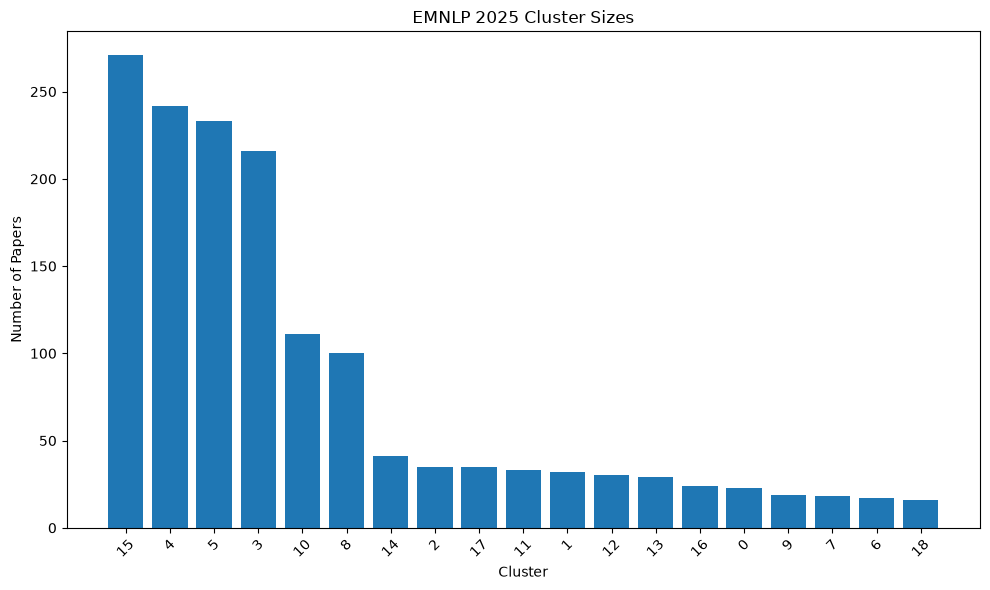

In [10]:
plot_df = (
    cluster_sizes[
        cluster_sizes["cluster"] != -1
    ]
    .sort_values("n_papers", ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    plot_df["cluster"].astype(str),
    plot_df["n_papers"]
)

ax.set_title("EMNLP 2025 Cluster Sizes")
ax.set_xlabel("Cluster")
ax.set_ylabel("Number of Papers")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
